In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
plt.style.use('ggplot')
# pd.set_option('max_columns', 200)

In [2]:
df = pd.read_csv('coaster_db.csv')

In [3]:
df.shape

(990, 7)

In [4]:
df.head(5)

,Coaster_Name,Location,Status,Manufacturer,Year_Introduced,Opening_Date,Speed_mph
0,Switchback Railway,Coney Island,Removed,LaMarcus Adna Thompson,1884,1884-06-16,6.0
1,Flip Flap Railway,Sea Lion Park,Removed,Lina Beecher,1895,1895-01-01,NaN
2,Switchback Railway (Euclid Beach Park),"Cleveland, Ohio, United States",Closed,NaN,1896,NaN,NaN
3,Loop the Loop (Coney Island),Other,Removed,Edwin Prescott,1901,1901-01-01,NaN
4,Loop the Loop (Young's Pier),Other,Removed,Edwin Prescott,1901,1901-01-01,NaN


In [5]:
df.columns

Index(['Coaster_Name', 'Location', 'Status', 'Manufacturer', 'Year_Introduced',
       'Opening_Date', 'Speed_mph'],
      dtype='str')

In [6]:
df.dtypes

Coaster_Name           str
Location               str
Status                 str
Manufacturer           str
Year_Introduced      int64
Opening_Date           str
Speed_mph          float64
dtype: object

In [7]:
df.describe()

,Year_Introduced,Speed_mph
count,990.000000,850.000000
mean,1994.054545,49.017647
std,23.872027,16.847266
min,1884.000000,5.000000
25%,1988.000000,37.300000
50%,2000.000000,50.000000
75%,2009.000000,58.000000
max,2022.000000,149.100000


In [8]:
# Example of dropping columns
# df.drop(['Opening date'], axis=1)

In [ ]:
df = df[['coaster_name',
    # 'Length', 'Speed',
    'Location', 'Status',
    # 'Opening date',
    #   'Type',
    'Manufacturer',
#     'Height restriction', 'Model', 'Height',
#        'Inversions', 'Lift/launch system', 'Cost', 'Trains', 'Park section',
#        'Duration', 'Capacity', 'G-force', 'Designer', 'Max vertical angle',
#        'Drop', 'Soft opening date', 'Fast Lane available', 'Replaced',
#        'Track layout', 'Fastrack available', 'Soft opening date.1',
#        'Closing date',
         'year_introduced',
        'latitude', 'longitude',
    'Type_Main',
       'opening_date_clean',
    #'speed1', 'speed2', 'speed1_value', 'speed1_unit',
       'speed_mph', 
     'Inversions_clean', 'Gforce_clean']].copy()

In [56]:
# Rename our columns
df = df.rename(columns={'coaster_name':'Coaster_Name',
                   'year_introduced':'Year_Introduced',
                   'opening_date_clean':'Opening_Date',
                   'speed_mph':'Speed_mph'})

In [57]:
df.isna().sum()

Coaster_Name         0
Location             0
Status             146
Manufacturer        58
Year_Introduced      0
Opening_Date       183
Speed_mph          140
dtype: int64

In [14]:
df.loc[df.duplicated()]

,Coaster_Name,Location,Status,Manufacturer,Year_Introduced,Opening_Date,Speed_mph


In [15]:
# Check for duplicate coaster name
df.loc[df.duplicated(subset=['Coaster_Name'])].head(5)

,Coaster_Name,Location,Status,Manufacturer,Year_Introduced,Opening_Date,Speed_mph


In [16]:
# Checking an example duplicate
df.query('Coaster_Name == "Crystal Beach Cyclone"')

,Coaster_Name,Location,Status,Manufacturer,Year_Introduced,Opening_Date,Speed_mph
39,Crystal Beach Cyclone,Crystal Beach Park,Removed,Traver Engineering,1926,1926-01-01,60.0


In [17]:
df.columns

Index(['Coaster_Name', 'Location', 'Status', 'Manufacturer', 'Year_Introduced',
       'Opening_Date', 'Speed_mph'],
      dtype='str')

In [18]:
df = df.loc[~df.duplicated(subset=['Coaster_Name','Location','Opening_Date'])] \
    .reset_index(drop=True).copy()

In [19]:
df['Year_Introduced'].value_counts()

Year_Introduced
1999    46
2000    45
1998    30
2001    29
2002    28
        ..
1952     1
1955     1
1956     1
1959     1
1961     1
Name: count, Length: 101, dtype: int64

Text(0, 0.5, 'Count')

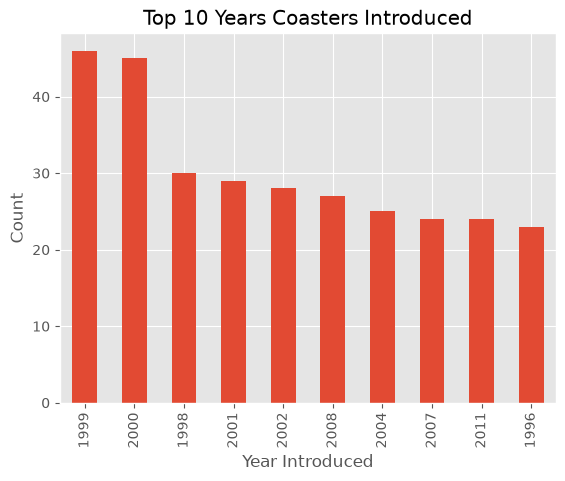

In [20]:
ax = df['Year_Introduced'].value_counts() \
    .head(10) \
    .plot(kind='bar', title='Top 10 Years Coasters Introduced')
ax.set_xlabel('Year Introduced')
ax.set_ylabel('Count')

Text(0.5, 0, 'Speed (mph)')

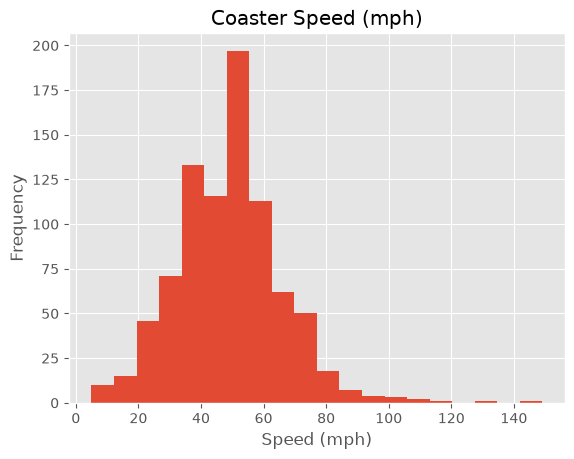

In [21]:
ax = df['Speed_mph'].plot(kind='hist',
                          bins=20,
                          title='Coaster Speed (mph)')
ax.set_xlabel('Speed (mph)')

Text(0.5, 0, 'Speed (mph)')

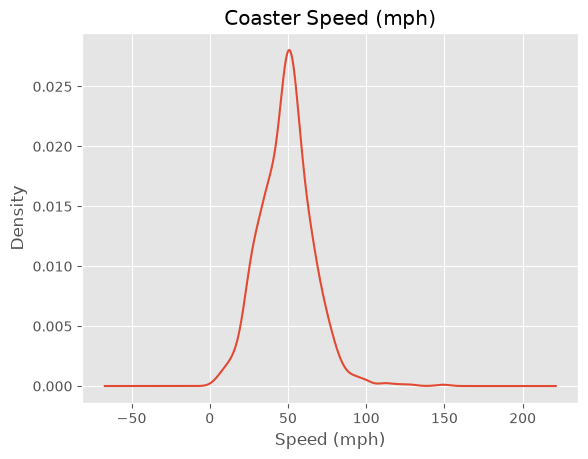

In [22]:
ax = df['Speed_mph'].plot(kind='kde',
                          title='Coaster Speed (mph)')
ax.set_xlabel('Speed (mph)')

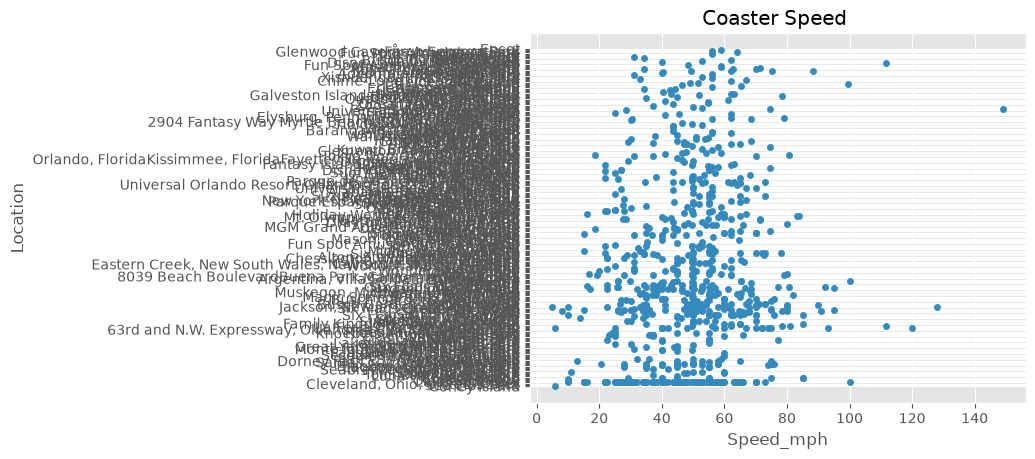

In [53]:
df.plot(kind='scatter',
        x='Speed_mph',
        y='Location',
        title='Coaster Speed ')
plt.show()

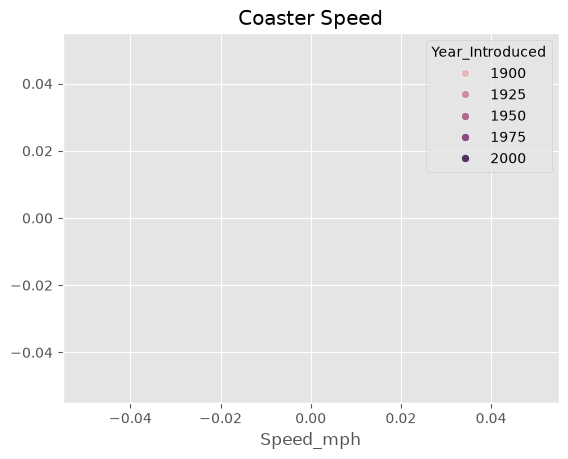

In [65]:
ax = sns.scatterplot(x='Speed_mph',
                hue='Year_Introduced',
                data=df)
ax.set_title('Coaster Speed')
plt.show()

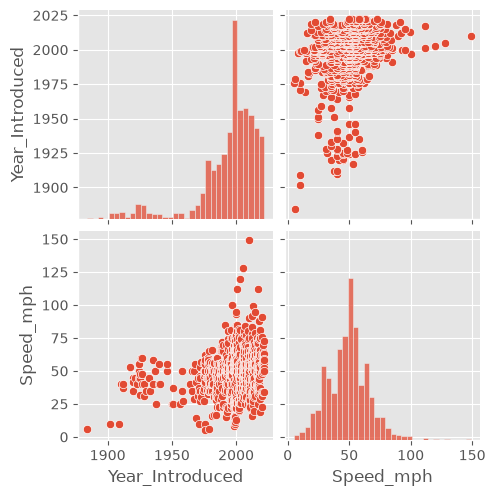

In [41]:
sns.pairplot(df,
             vars=['Year_Introduced','Speed_mph'])
           
plt.show()

In [32]:
df_corr = df[['Year_Introduced','Speed_mph']].dropna().corr()
df_corr

,Year_Introduced,Speed_mph
Year_Introduced,1.000000,0.225991
Speed_mph,0.225991,1.000000


<Axes: >

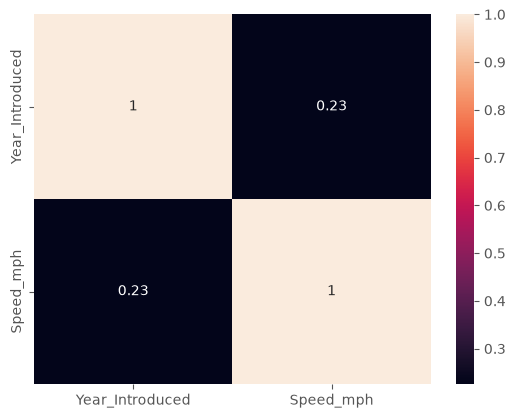

In [33]:
sns.heatmap(df_corr, annot=True)

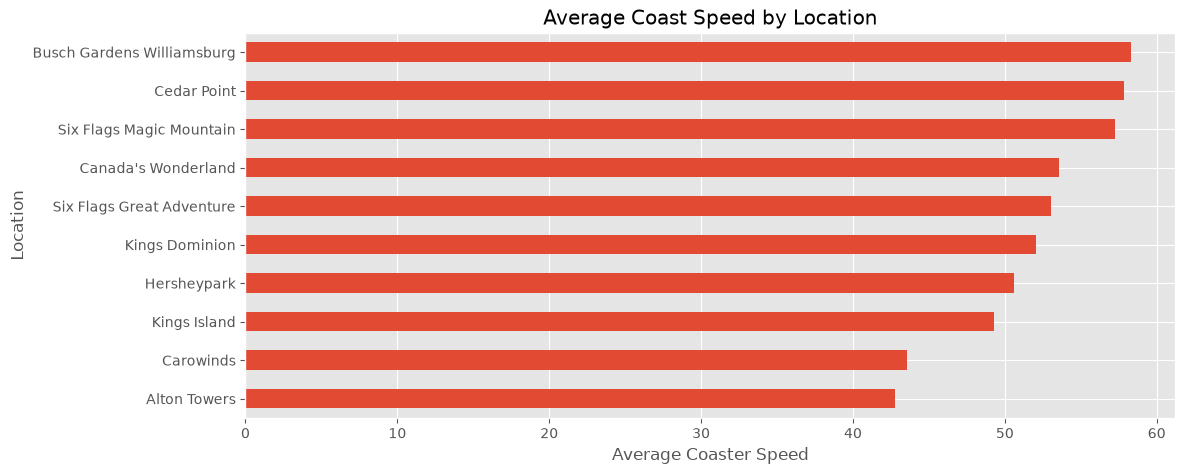

In [31]:
ax = df.query('Location != "Other"') \
    .groupby('Location')['Speed_mph'] \
    .agg(['mean','count']) \
    .query('count >= 10') \
    .sort_values('mean')['mean'] \
    .plot(kind='barh', figsize=(12, 5), title='Average Coast Speed by Location')
ax.set_xlabel('Average Coaster Speed')
plt.show()